# LLMSTU tuning — optimize crops, prompts & caption schema
Run this BEFORE the full run. It sweeps crop configs and caption prompts on a small
sample and gives you HTML reports to pick the best settings. Use your **~95GB GPU**
runtime (Runtime → Change runtime type), the same card you'll do the full run on.

Everything runs the model **on the GPU** — no inference API is called.

In [1]:
!rm -rf /content/LLMSTU-pipeline

In [2]:
# --- Get the repo into Colab ---
# Set REPO to your GitHub repo. If it is PRIVATE, add a GitHub token to Colab
# Secrets (left sidebar, key icon) as GITHUB_TOKEN (scope: repo). Public repos
# clone without a token. Leave REPO="" if you uploaded the folder manually.
REPO = "vaelkokach/LLMSTU-pipeline"
import os
from google.colab import userdata

def _secret(name):
    try: return userdata.get(name)
    except Exception: return None

if REPO and not os.path.isdir("/content/LLMSTU-pipeline"):
    gh = _secret("GITHUB_TOKEN")
    auth = f"{gh}@" if gh else ""              # token only used if repo is private
    !git clone https://{auth}github.com/{REPO}.git /content/LLMSTU-pipeline
%cd /content/LLMSTU-pipeline

!pip install -q "ultralytics>=8.3.0" "transformers>=4.57.0" accelerate "bitsandbytes>=0.43.0" \
    "huggingface_hub>=0.35.0" pandas pyarrow pyyaml pillow
from huggingface_hub import login
login(_secret("HF_TOKEN"))

Cloning into '/content/LLMSTU-pipeline'...
remote: Enumerating objects: 103, done.
remote: Counting objects: 100% (103/103), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 103 (delta 49), reused 84 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (103/103), 58.72 KiB | 4.19 MiB/s, done.
Resolving deltas: 100% (49/49), done.
/content/LLMSTU-pipeline
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 83.4 MB/s eta 0:00:00


## 1. Grab a small sample of frames to tune on

In [3]:
from pathlib import Path
from llmstu import dataset_io as io
from llmstu.config import load
cfg = load('config.yaml')
# Tuning needs only a few frames -> download N random files (seconds), not a whole
# 5000-file shard. shard=None samples across ALL 21 shards for max variety.
N = 50
frames_dir = io.download_frame_sample(cfg.data.source_repo, cfg.data.source_subdir,
                                      Path('work/frames_dl'), n=N, token=None,
                                      shard=None, seed=0)   # seed=None -> first N (no shuffle)
print('frames at', frames_dir, '| files:', len(list(frames_dir.glob('**/*.jpg'))))


frames/shard_010/t000625_568_f007740.jpg: reconstructing file:   0%|          |  0.00B /  339kB            

frames/shard_010/t000625_568_f007740.jpg: downloading bytes:           |  0.00B            

frames/shard_019/t001548_083_f019020.jpg: reconstructing file:   0%|          |  0.00B /  356kB            

frames/shard_019/t001548_083_f019020.jpg: downloading bytes:           |  0.00B            

frames/shard_011/t000700_948_f008417.jpg: reconstructing file:   0%|          |  0.00B /  378kB            

frames/shard_011/t000700_948_f008417.jpg: downloading bytes:           |  0.00B            

... (91 outputs left out)

frames/shard_000/t000013_373_f000266.jpg: downloading bytes:           |  0.00B            

frames/shard_002/t000132_958_f001860.jpg: reconstructing file:   0%|          |  0.00B /  345kB            

frames/shard_002/t000132_958_f001860.jpg: downloading bytes:           |  0.00B            

[io] sampled 50 frames from all shards (seed=0) -> work/frames_dl/frames
frames at work/frames_dl/frames | files: 50


## 2. Tune CROPS
Edit `experiments.yaml` (crop_variants), then run. Open the HTML it writes to compare
tightness / coverage / crops-per-frame, and copy the winner into `config.yaml` (crop:).

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[tune-crops] tight_head: 88 crops from 8 frames (avg 11.0/frame)
[tune-crops] default_head_wide: 90 crops from 8 frames (avg 11.2/frame)
[tune-crops] wide_context: 95 crops from 8 frames (avg 11.9/frame)
[tune-crops] upper_body: 90 crops from 8 frames (avg 11.2/frame)
[tune-crops] default_head_wide_bigdet: 94 crops from 8 frames (avg 11.8/frame)
[tune-crops] report -> work/tune/crops_report.html



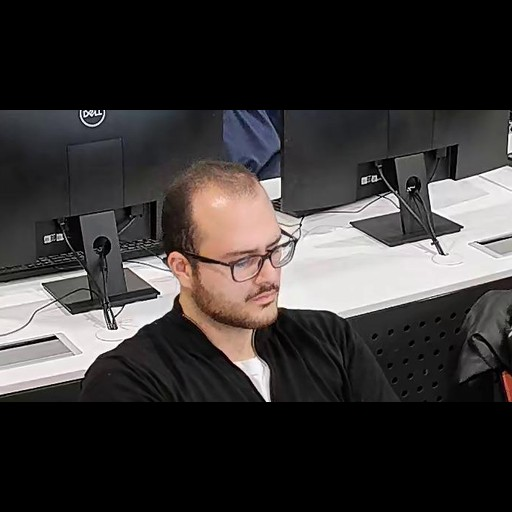
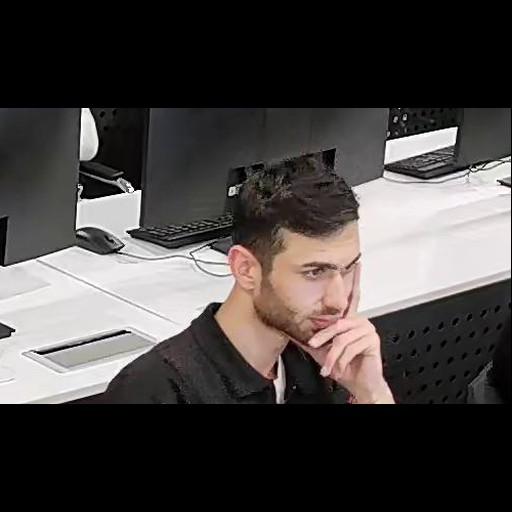
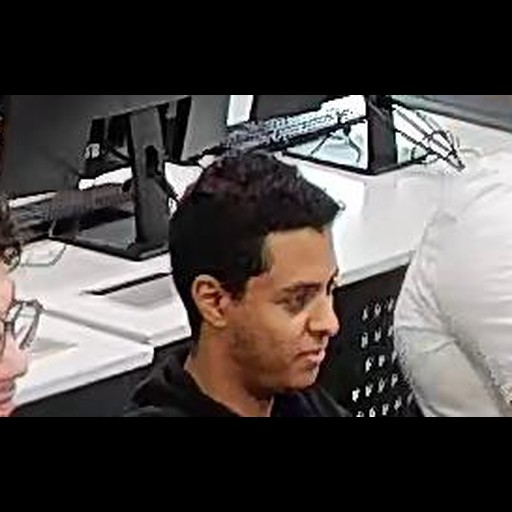
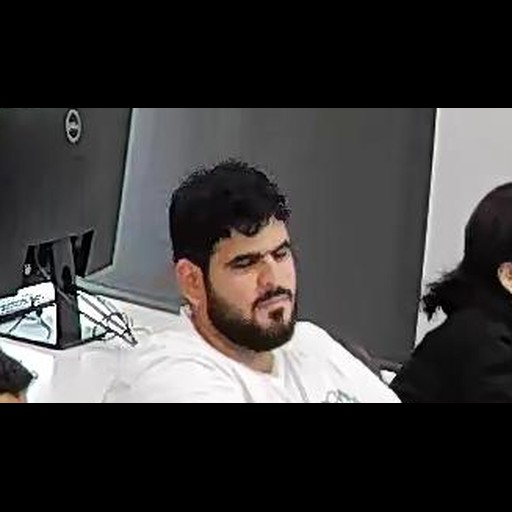
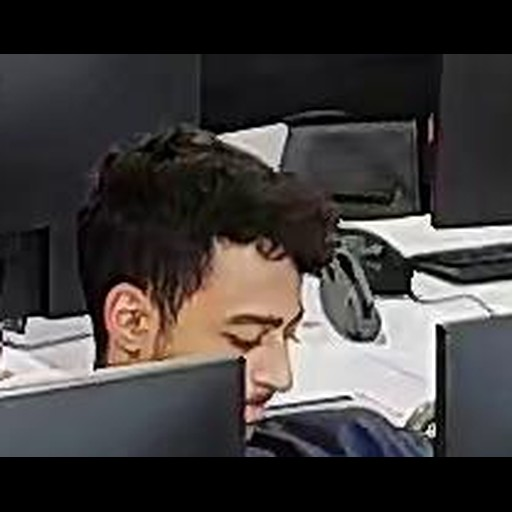
...
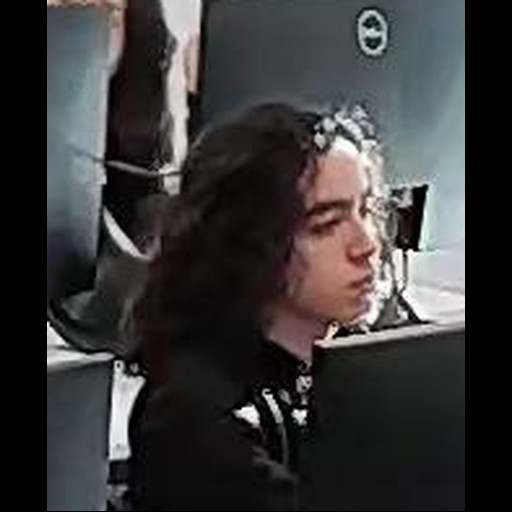
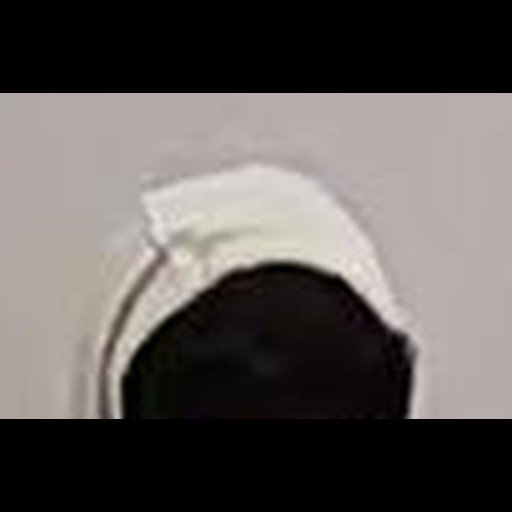
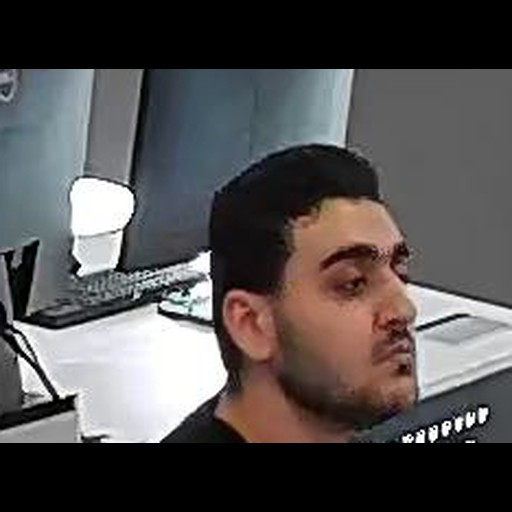
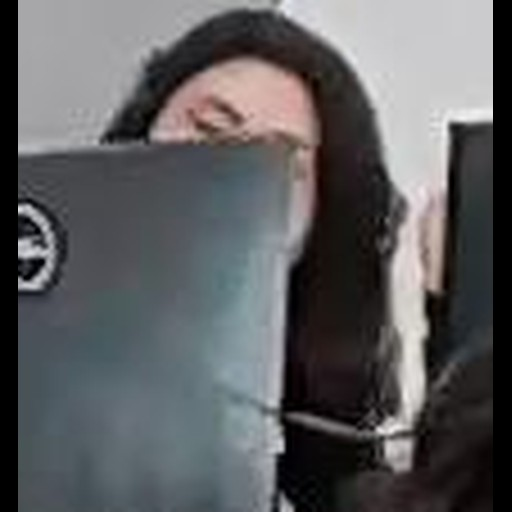
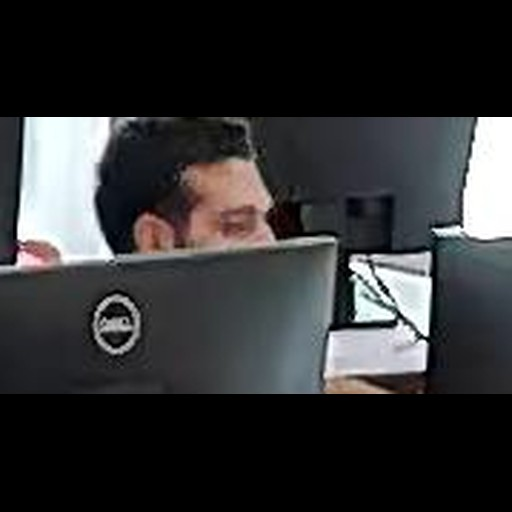

In [4]:
!python scripts/05_tune_crops.py --frames work/frames_dl --n-frames 8
from IPython.display import HTML
HTML(open('work/tune/crops_report.html').read())

## 3. Make a small crop set for caption tuning
First copy your winning crop settings from step 2 into `config.yaml` (crop:), then run
this — it uses `config.yaml` to make ~30 crops for the caption sweep.

In [5]:
from llmstu import crop as crop_mod
crop_mod.run(io.iter_frames(frames_dir, cfg.data.frames_glob), Path('work/tune_crops'),
             cfg.crop, manifest_path=Path('work/tune_crops_manifest.jsonl'))

[crop] wrote 471 crops -> work/tune_crops


PosixPath('work/tune_crops_manifest.jsonl')

## 4. Tune CAPTIONS (prompt / schema / model)
Edit `experiments.yaml` (caption_variants). These ship with `load_in_4bit: false` to
match your 95GB bf16 production config. Each variant loads its model in turn, so keep
`--n-crops` small (16–32). The report highlights where variants DISAGREE and shows
per-field agreement (agreement = consistency, not correctness — judge correctness by
eye against the thumbnails).

[tune-caps] loading p_structured (Qwen/Qwen3.5-27B, prompt=v1_structured, 4bit=False)
[caption] flash-attn not installed; falling back to attn_implementation='sdpa'
config.json: 100% 4.13k/4.13k [00:00<00:00, 2.93MB/s]
model.safetensors.index.json: 100% 127k/127k [00:00<00:00, 517MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0% 0/11 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/10.7G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/32.1G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/42.7G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/42.7G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/42.7G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/42.7G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/42.7G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/42.7G [00:00<?, ?B/s]
Reconstructing (in

field,% crops where all variants agree
activity,46%
gaze_direction,42%
attention_target,50%
engagement_level,67%
posture,62%
hand_state,88%
phone_visible,100%
laptop_visible,75%
talking,100%
occluded,92%

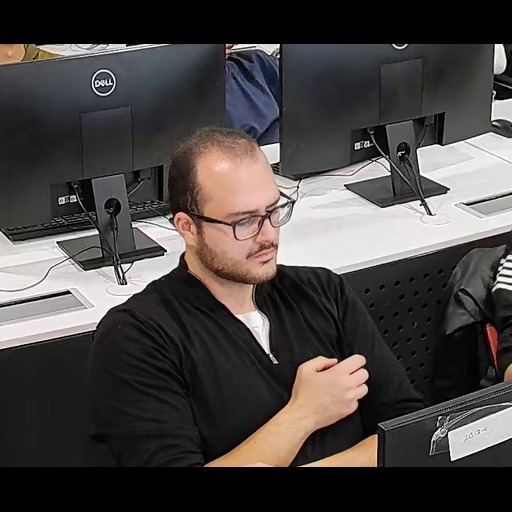
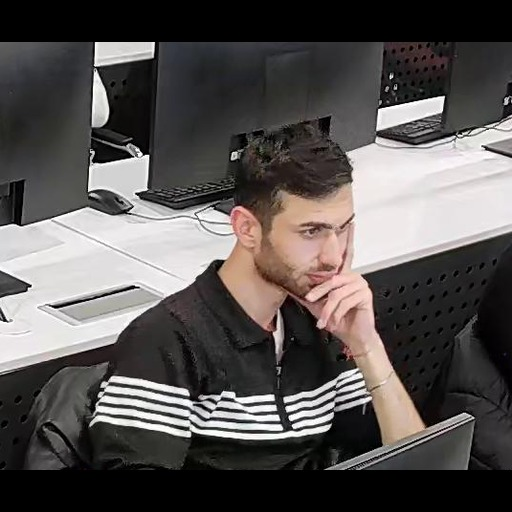
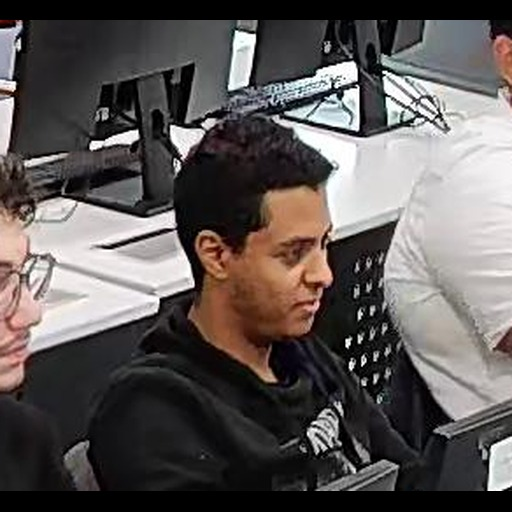
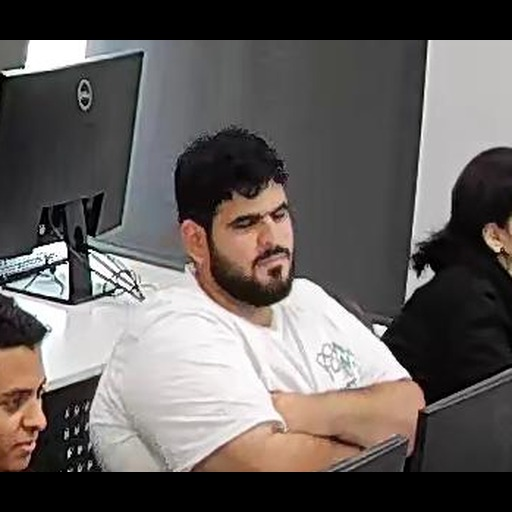
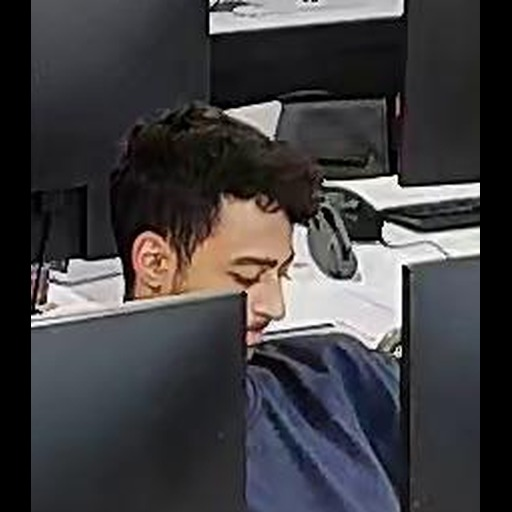
...
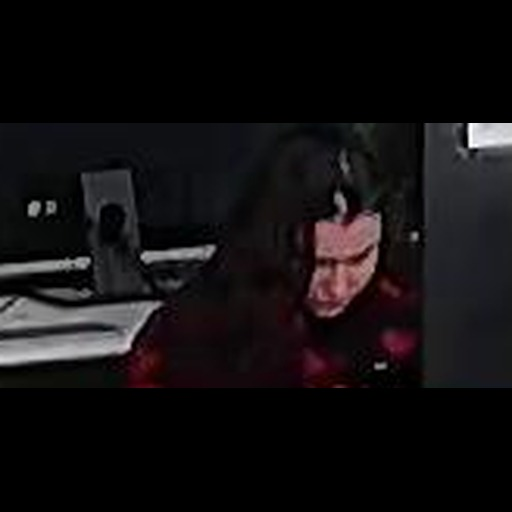
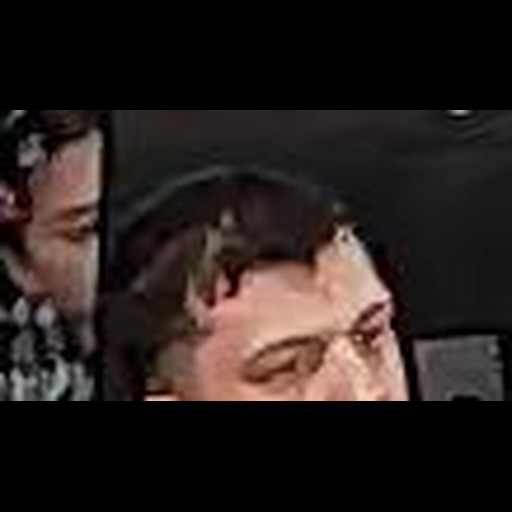
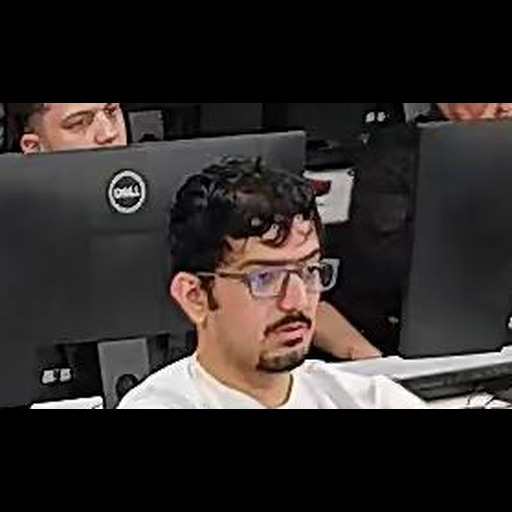
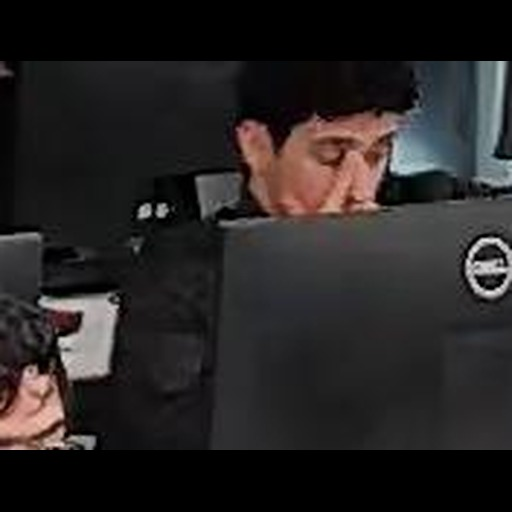
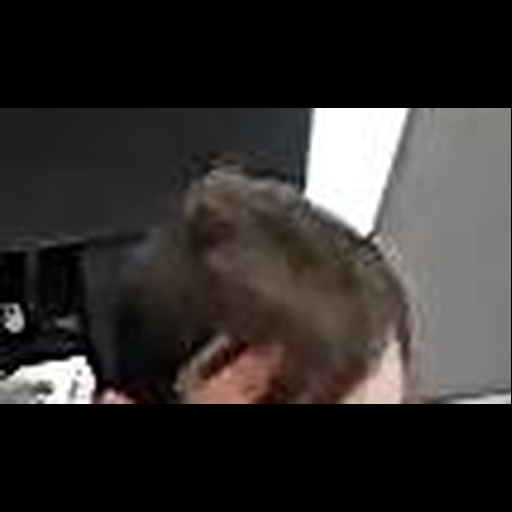

In [6]:
!python scripts/06_tune_captions.py --crops work/tune_crops --n-crops 24
from IPython.display import HTML
HTML(open('work/tune/captions_report.html').read())

## 5. Lock in your choices
Edit `config.yaml`:
- `crop:` -> winning crop settings
- `caption.prompt_name` -> best prompt, `caption.model_id` -> final model
- adjust `llmstu/schema.py` if you want to add/remove label fields

Then move to the **final run** notebook (`LLMSTU_pipeline_colab.ipynb`) and see
`docs/COLAB_A100.md` for max-efficiency settings.

In [8]:
!python scripts/08_tune_schema.py --crops work/tune_crops --n-crops 24

[tune-schema] s_full (schema=full, model=Qwen/Qwen3.5-27B)
[caption] flash-attn not installed; falling back to attn_implementation='sdpa'
[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d
Loading weights: 100% 1184/1184 [00:03<00:00, 304.96it/s]
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[tune-schema] s_no_attn_gaze_merged (schema=no_attn_gaze_merged, model=Qwen/Qwen3.5-27B)
[caption] flash-attn not installed; falling back to attn_implementation='sdpa'
Loading weights: 100% 1184/1184 [00:03<00:00, 304.19it/s]
[transformers] Kwargs passed to `processor.__call__` 